In [2]:
from pathlib import Path

DATASET_ROOT = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set")
SPLITS = ["Train", "Val"]
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]


## 2.1 — Locate "wrong-folder" files

Files whose *entire* label content is a class that doesn't match their folder
(e.g. only `class 3` boxes inside Meningioma/). We'll list and visualize them
to decide: move to correct folder, or drop.

In [3]:
# Report, for every (split, class), any file whose class_ids are a strict subset
# of {other classes} — i.e. contains zero boxes of its own class.
CLASSES_ID = {"Glioma": 0, "Meningioma": 1, "No Tumor": 2, "Pituitary": 3}

suspects = []
for s in SPLITS:
    for c in CLASSES:
        own_id = CLASSES_ID[c]
        for txt in (DATASET_ROOT / s / c / "labels").glob("*.txt"):
            ids = [int(float(ln.split()[0])) for ln in txt.read_text().splitlines() if ln.strip()]
            if ids and own_id not in ids:
                suspects.append({"split": s, "folder": c, "file": txt.name,
                                 "class_ids_in_label": sorted(set(ids))})

import pandas as pd
suspect_df = pd.DataFrame(suspects)
print(f"Total wrong-folder suspects: {len(suspect_df)}\n")
display(suspect_df)

Total wrong-folder suspects: 15



,split,folder,file,class_ids_in_label
0,Train,Glioma,gg (278).txt,[3]
1,Train,Glioma,Te-gl_0043.txt,[1]
2,Train,Glioma,Tr-gl_1167.txt,[1]
3,Train,Meningioma,m (49).txt,[3]
4,Train,Meningioma,m (50).txt,[3]
5,Train,Meningioma,m (51).txt,[3]
6,Train,Meningioma,m (52).txt,[3]
7,Train,Meningioma,m (53).txt,[3]
8,Train,Meningioma,m (54).txt,[3]
9,Train,Meningioma,m (55).txt,[3]


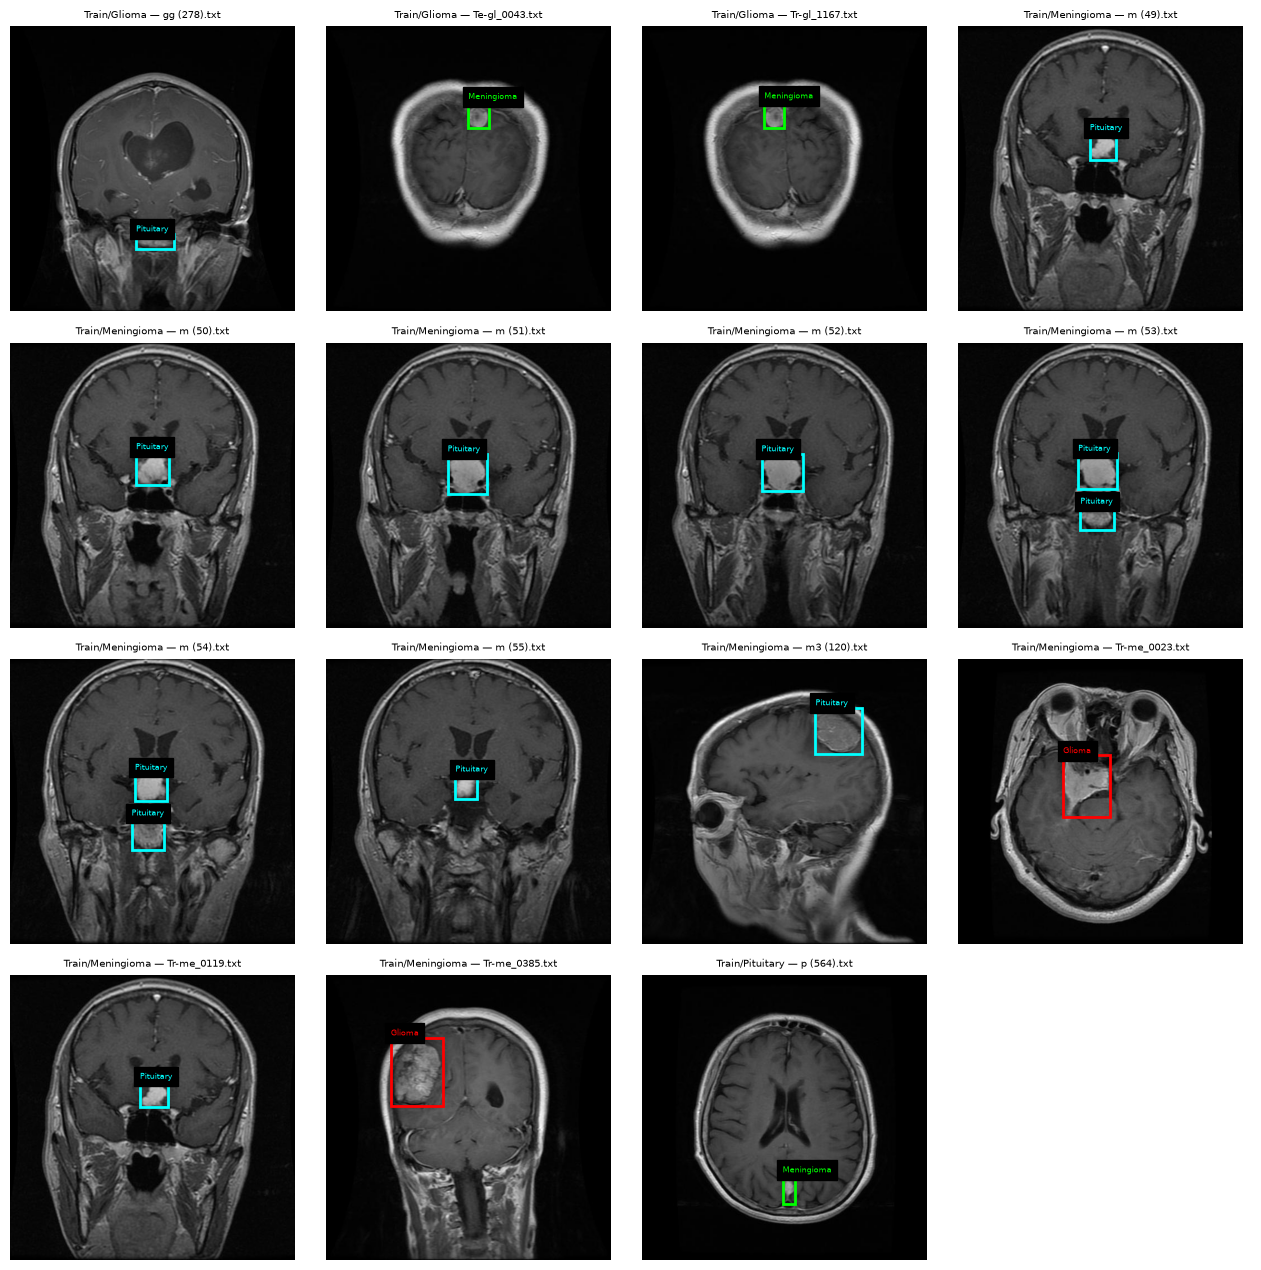

In [4]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

ID_COLORS = {0:"red",1:"lime",2:"orange",3:"cyan"}
ID_NAMES  = {0:"Glioma",1:"Meningioma",2:"No Tumor",3:"Pituitary"}

def load_labels(p):
    return [tuple(float(v) for v in ln.split()) for ln in p.read_text().splitlines() if ln.strip()]

n = len(suspect_df)
cols = 4
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols*3.2, rows*3.2))
axes = axes.flatten()

for i, row in suspect_df.reset_index(drop=True).iterrows():
    base = DATASET_ROOT / row["split"] / row["folder"]
    ip = base / "images" / f"{Path(row['file']).stem}.jpg"
    lp = base / "labels" / row["file"]
    ax = axes[i]
    img = Image.open(ip).convert("RGB"); W, H = img.size
    ax.imshow(img); ax.axis("off")
    for cid, xc, yc, w, h in load_labels(lp):
        x0, y0 = (xc-w/2)*W, (yc-h/2)*H
        ax.add_patch(patches.Rectangle((x0,y0), w*W, h*H, lw=2,
                      edgecolor=ID_COLORS.get(int(cid),"white"), fill=False))
        ax.text(x0, y0-4, ID_NAMES.get(int(cid), str(int(cid))),
                color=ID_COLORS.get(int(cid),"white"), fontsize=6, backgroundcolor="black")
    ax.set_title(f"{row['split']}/{row['folder']} — {row['file']}", fontsize=7)

for j in range(len(suspect_df), len(axes)):
    axes[j].axis("off")
plt.tight_layout(); plt.show()

## 2.2 — Verify cleanup

Re-run 1.3 + 1.4 counts against `data_set_clean/`. Confirm:
- 15 suspects resolved (0 remaining wrong-folder files)
- Val/No Tumor: 100 images / 100 labels (perfect pairing)
- Class-3 still present in Pituitary folder (we didn't touch those)

In [5]:
CLEAN = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_clean")
CLASSES_ID = {"Glioma": 0, "Meningioma": 1, "No Tumor": 2, "Pituitary": 3}

# 1) counts
rows = []
for s in SPLITS:
    for c in CLASSES:
        base = CLEAN / s / c
        imgs = {p.stem for p in (base/"images").glob("*.jpg")}
        lbls = {p.stem for p in (base/"labels").glob("*.txt")}
        rows.append({"split": s, "class": c,
                     "images": len(imgs), "labels": len(lbls),
                     "img_no_lbl": len(imgs-lbls), "lbl_no_img": len(lbls-imgs)})
print("=== Counts ===")
display(pd.DataFrame(rows))

# 2) residual wrong-folder files
res = []
for s in SPLITS:
    for c in CLASSES:
        own = CLASSES_ID[c]
        for txt in (CLEAN/s/c/"labels").glob("*.txt"):
            ids = [int(float(ln.split()[0])) for ln in txt.read_text().splitlines() if ln.strip()]
            if ids and own not in ids:
                res.append((s, c, txt.name, sorted(set(ids))))
print(f"\n=== Residual wrong-folder files: {len(res)} ===")
for r in res: print(r)

=== Counts ===


,split,class,images,labels,img_no_lbl,lbl_no_img
0,Train,Glioma,1152,1152,0,0
1,Train,Meningioma,1442,1442,0,0
2,Train,No Tumor,711,711,0,0
3,Train,Pituitary,1432,1432,0,0
4,Val,Glioma,135,135,0,0
5,Val,Meningioma,140,140,0,0
6,Val,No Tumor,100,100,0,0
7,Val,Pituitary,136,136,0,0



=== Residual wrong-folder files: 0 ===
